# M5 validation error diagnostics

## tl;dr

- The supplied 126,000 forecast rows form 42,000 matched observations across 500 product–store series.
- Zero-sales days are 56.15% of these observations. LightGBM adds 929.2 absolute-error units on zero-sales days and saves 787.5 on positive-sales days: net +141.7 versus mean28.
- LightGBM wins on 219 series and loses on 281. Its pooled MAE is 1.0588 versus 1.0554 for mean28.
- Next experiment: change only the LightGBM objective from Poisson to L1 and keep the data, features, and validation windows fixed. No improvement from L1 has yet been measured.


## Context & Methods

Metric: observed unit-sales MAE. Comparison: paired LightGBM minus mean28 absolute errors. Evaluation origins: 2016-01-31, 2016-02-28, and 2016-03-27, each with a 28-day horizon. The final holdout is excluded.

### Key assumptions

- All models use identical series, target dates, and actual sales. Data-contract assertions verify this.
- Zero/positive sales groups are retrospective diagnostic labels. They must never be used as future model-routing inputs.
- Error contributions are an accounting decomposition, not proof of a causal training mechanism.
- This is a sampled M5 population, not an official WRMSSE evaluation.

Source: the user-provided `predictions.csv`, generated by DemandCast v0.1. The notebook prints its checksum below. Original training history is not supplied, so the L1 M5 experiment is deferred to the local project.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from analysis.error_diagnostics import analyze, save_results, plot_diagnostics

PREDICTIONS_PATH = PROJECT_ROOT / "outputs/m5-validation/predictions.csv"
OUTPUT_PATH = PROJECT_ROOT / "reports/v01_diagnostics"


## Data

The input remains one row per series, cutoff, date, and model. Paired observations remove the model replication before computing sales volume and zero-sales prevalence.

In [2]:
summary, tables, paired = analyze(PREDICTIONS_PATH)
save_results(summary, tables, OUTPUT_PATH)
for name in ["source_sha256", "input_rows", "paired_observations", "n_series", "cutoffs"]:
    print(f"{name}: {summary[name]}")


source_sha256: 502fe4d34ae3e81c9c7cf3cac73a63e0971378dbbddfedb247cff95596b11bf2
input_rows: 126000
paired_observations: 42000
n_series: 500
cutoffs: ['2016-01-31', '2016-02-28', '2016-03-27']


## Results

### Horizon comparison

Bands have different row counts: 1–7 and 8–14 each have 10,500 observations; 15–28 has 21,000.

,horizon_band,model,n_observations,mae,wape,bias
0,1-7,seasonal_naive,10500,1.23276,0.91380,-0.03086
1,1-7,mean28,10500,1.02609,0.76060,0.00069
2,1-7,lightgbm,10500,1.02055,0.75650,-0.03308
3,8-14,seasonal_naive,10500,1.27400,0.89156,-0.11076
4,8-14,mean28,10500,1.07315,0.75101,-0.07921
5,8-14,lightgbm,10500,1.08828,0.76159,-0.08614
6,15-28,seasonal_naive,21000,1.25267,0.94510,-0.00724
7,15-28,mean28,21000,1.06121,0.80066,0.02431
8,15-28,lightgbm,21000,1.06317,0.80213,-0.04086


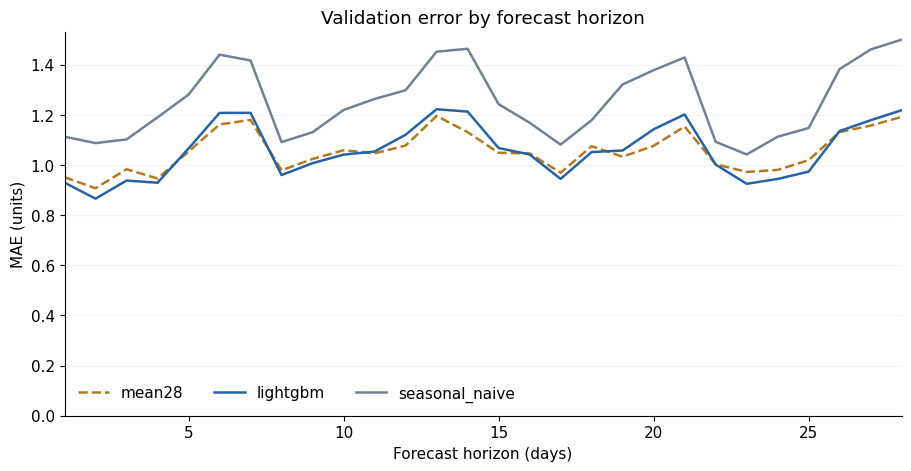

In [3]:
display(tables["horizon_band_metrics"][["horizon_band", "model", "n_observations", "mae", "wape", "bias"]].round(5))
figures = plot_diagnostics(tables)
for name, figure in figures.items():
    figure.savefig(OUTPUT_PATH / f"{name}.png", dpi=170)
plt.close("all")
display(figures["horizon_mae"])


### Zero-sales decomposition

Positive values below mean LightGBM has more absolute error than mean28. The two mutually exclusive contributions add exactly to the pooled gap.

,sales_state,n_observations,actual_sales,zero_fraction,mae_lightgbm,mae_mean28,net_extra_absolute_error
0,Positive sales,18416,57003.0,0.0,1.5813,1.6240,-787.5096
1,Zero sales,23584,0.0,1.0,0.6508,0.6114,929.2187


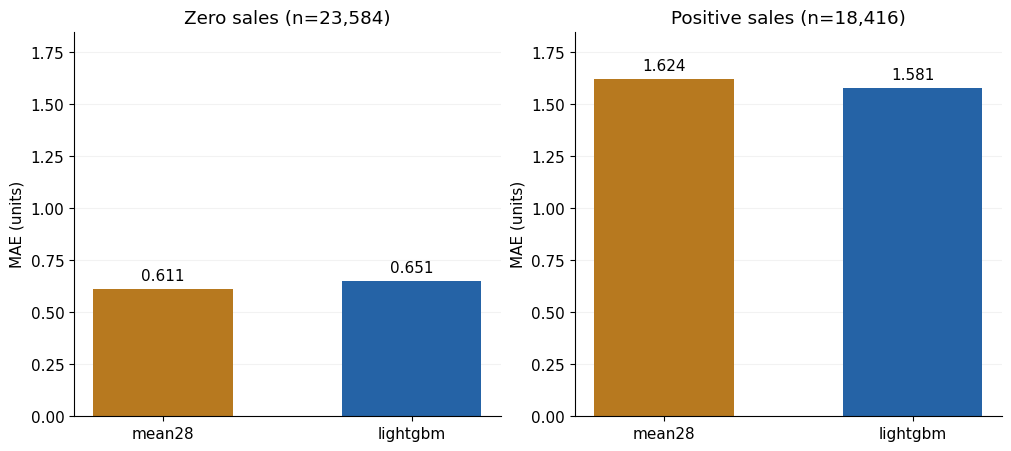

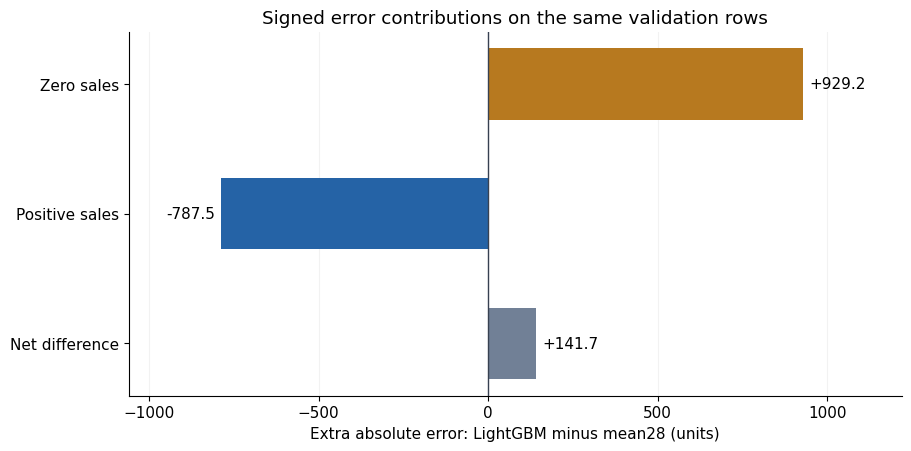

In [4]:
display(tables["sales_state_decomposition"].round(4))
display(figures["sales_state_mae"])
display(figures["error_contributions"])


### Category and series checks

These slices locate the gap; they do not establish why the objective or features caused it. M5 category/store labels are parsed from the original evaluation-series identifiers and checked.

In [5]:
display(tables["category_decomposition"].round(4))
print(f"Series wins/losses/ties: {summary["lgb_series_wins"]}/{summary["lgb_series_losses"]}/{summary["lgb_series_ties"]}")
print(f"Top 50 series share of LightGBM absolute error: {summary["top50_absolute_error_share"]:.2%}")
display(tables["largest_regressions"].head(5).round(4))
display(tables["largest_improvements"].head(5).round(4))


,category,n_observations,actual_sales,zero_fraction,mae_lightgbm,mae_mean28,net_extra_absolute_error
0,FOODS,18984,36816.0,0.4785,1.3581,1.3604,-43.7595
1,HOBBIES,7392,5476.0,0.7001,0.8383,0.8204,132.0190
2,HOUSEHOLD,15624,14711.0,0.5968,0.7994,0.7960,53.4496


Series wins/losses/ties: 219/281/0
Top 50 series share of LightGBM absolute error: 34.64%


,unique_id,n_observations,actual_sales,zero_fraction,mae_lightgbm,mae_mean28,absolute_error_lightgbm,net_extra_absolute_error,mae_difference
0,FOODS_3_090_CA_4_evaluation,84,2329.0,0.0000,9.9815,8.9337,838.4437,88.0152,1.0478
1,FOODS_2_011_WI_1_evaluation,84,89.0,0.3810,1.9345,0.9524,162.4946,82.4946,0.9821
2,FOODS_3_589_CA_4_evaluation,84,0.0,1.0000,0.5704,0.0000,47.9151,47.9151,0.5704
3,FOODS_3_561_CA_2_evaluation,84,412.0,0.0119,3.4443,2.8920,289.3251,46.3965,0.5523
4,HOUSEHOLD_2_447_CA_2_evaluation,84,140.0,0.4881,2.5485,2.1003,214.0720,37.6435,0.4481


,unique_id,n_observations,actual_sales,zero_fraction,mae_lightgbm,mae_mean28,absolute_error_lightgbm,net_extra_absolute_error,mae_difference
0,FOODS_3_120_CA_2_evaluation,84,1404.0,0.1905,7.7105,11.1318,647.6806,-287.3908,-3.4213
1,FOODS_1_204_WI_3_evaluation,84,386.0,0.2976,4.3372,5.5961,364.3231,-105.7483,-1.2589
2,FOODS_3_039_WI_1_evaluation,84,596.0,0.0000,2.9830,3.7092,250.5735,-60.9979,-0.7262
3,FOODS_3_524_CA_1_evaluation,84,725.0,0.2857,6.8345,7.4804,574.0975,-54.2597,-0.6459
4,FOODS_3_307_CA_2_evaluation,84,398.0,0.0714,2.0090,2.5034,168.7546,-41.5311,-0.4944


## Takeaways

1. The small pooled deficit hides offsetting behavior on zero and positive sales.
2. LightGBM-L1 is a defensible single-change hypothesis because L1 directly targets absolute error. The output tables alone cannot prove that changing the objective will improve forecasts.
3. Compare the new model with mean28 and the reproduced Poisson control on the same three validation folds. Inspect signed bias and positive-sales MAE; a lower aggregate MAE does not establish a suitable inventory policy.
4. Do not use the already observed holdout to tune this experiment.

Technical source: [LightGBM objective definitions](https://lightgbm.readthedocs.io/en/stable/Parameters.html). Run `experiments/run_l1_ablation.py` in the original DemandCast environment to evaluate the hypothesis.
